# Source optimization (SO lite)

The illumination is the cheapest knob of a scanner: a programmable
illuminator (a micro mirror array) can shape the source into almost any
pattern. Which source is best for a given set of patterns?

In Abbe's method the image is an incoherent sum over the source points, so
it is **linear in the source weights**:

$$I(x) = \sum_g W_g\, I_g(x),$$

with $I_g$ the image of pixel (or symmetric pixel group) $g$ alone.
`pyoptics.litho.source_opt` uses this directly:

- `SourcePixels`: the pixels of a freeform source on the grid of the
  standard shapes, grouped by a symmetry (mirror x/y, and optionally the
  diagonals for patterns in both orientations); a group shares one weight.
- `SourceOptimizer`: computes, once, the intensity and the image slope of
  every group at the nominal edges of every clip and every focus. Any
  source is then rated in microseconds, and the source that maximizes the
  **worst NILS** over all clips and foci follows from linear programming.
  NILS $= \mathrm{CD}\cdot \partial_x I / I$ is a ratio of two linear
  functions of $W$; maximizing the minimum of such ratios is solved by
  bisection, each step a linear feasibility problem (`scipy.optimize.linprog`).
- Constraints: non-negative weights, symmetry, a **minimum pupil fill**
  (an illuminator cannot put all the light into a few pixels, and lens
  heating forbids it), and optionally a **common dose**: all clips print at
  size at the same threshold within a tolerance.

The NILS is evaluated at the nominal edges. Without the common dose
constraint each clip is assumed to be biased to size on the mask (its
threshold is the intensity at its nominal edge); the mask itself is not
optimized (no SMO, no OPC).

Setup: ArF water immersion, NA 1.35, 6 % attenuated PSM (thin mask), TE
(azimuthal) polarization, 45 nm lines from dense to isolated.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask
from pyoptics.litho import source_opt as so
from pyoptics.litho.plot import plot_source

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

projector = Projector(1.35, 193.0, n=1.437)
mask = ThinMask.att_psm()
POL = "TE"
template = Illumination.conventional(0.5, polarization=POL)  # only its polarization is used
pitches = [90.0, 130.0, 200.0, 400.0]
clips = {"{:.0f} nm pitch".format(p): LithoSimulation(MaskLayout.lines_spaces(p, 45.0), mask, template,
                                                       projector)
         for p in pitches}
N_SAMPLES = 25
pixels = so.SourcePixels(N_SAMPLES, symmetry="xy")
optimizer = so.SourceOptimizer(clips, pixels, foci=(0.0, 40.0))
t0 = time.time()
optimizer.responses
print("{} pixels in {} symmetric groups, responses of {} clips x {} foci in {:.2f} s".format(
    len(pixels.s_x), len(pixels), len(clips), len(optimizer.foci), time.time() - t0))

441 pixels in 123 symmetric groups, responses of 4 clips x 2 foci in 0.14 s


## 1. Linearity

The responses reproduce the full simulation for any source on the pixel
grid: `optimizer.nils(optimizer.project(ill))` against
`optimizer.evaluate(ill)`, which runs `LithoSimulation` with the source:

In [2]:
for ill in (Illumination.annular(0.9, 0.6, N_SAMPLES, polarization=POL),
            Illumination.dipole(0.9, 0.6, n_samples=N_SAMPLES, polarization=POL)):
    fast, full = optimizer.nils(optimizer.project(ill)), optimizer.evaluate(ill)
    print("{:22s} worst NILS {:.4f} (responses) vs {:.4f} (simulation), max difference {:.1e}".format(
        ill.name, fast.min(), full.min(), np.abs(fast - full).max()))

annular 0.6–0.9        worst NILS 1.1386 (responses) vs 1.1386 (simulation), max difference 2.4e-14
dipole x 0.6–0.9       worst NILS 1.8412 (responses) vs 1.8412 (simulation), max difference 1.3e-14


## 2. Where each pitch wants its light

The NILS of each pixel group *alone* shows which source positions help
which pattern. For lines along y only $s_x$ matters: the dense pitch
needs the two-beam positions where the 0th and a 1st order fall
symmetrically into the pupil ($s_x \approx \lambda/(2\,p\,\mathrm{NA})$),
while the isolated lines prefer other positions.

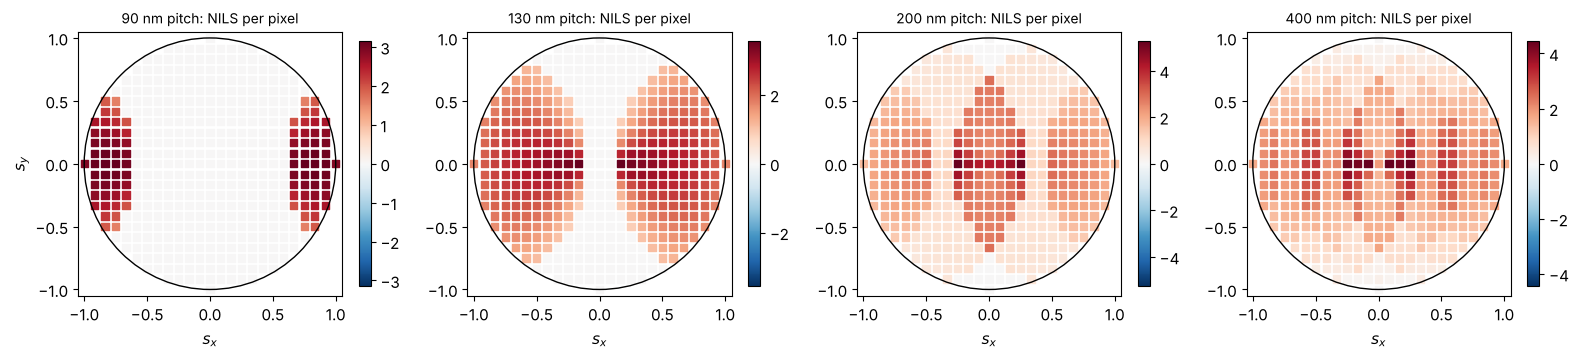

In [3]:
E, S, O = optimizer.responses
single = optimizer.cds[:, None, None]*S/E  # NILS of each group alone (clips, foci, groups)
fig, axes = plt.subplots(1, len(pitches), figsize=(4*len(pitches), 3.6))
for k, (ax, name) in enumerate(zip(axes, clips)):
    v = single[k, 0][pixels.group_of]
    sc = ax.scatter(pixels.s_x, pixels.s_y, c=v, s=28, marker="s", cmap="RdBu_r",
                    vmin=-np.abs(v).max(), vmax=np.abs(v).max())
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="k"))
    ax.set_aspect("equal"), ax.set_xlim(-1.05, 1.05), ax.set_ylim(-1.05, 1.05)
    ax.set_title(name + ": NILS per pixel", fontsize=10)
    ax.set_xlabel("$s_x$")
    plt.colorbar(sc, ax=ax, shrink=0.8)
axes[0].set_ylabel("$s_y$")
plt.tight_layout()

## 3. The optimized source

`optimize(min_fill)` maximizes the worst NILS over the four pitches at best
focus and 40 nm defocus. Without a pupil fill limit the optimum is a
vertex of the linear program: a few pixels. A minimum pupil fill spreads
the light and costs some NILS.

min fill 0.0: worst NILS 2.164, pupil fill 0.018  (0.02 s)
min fill 0.1: worst NILS 2.062, pupil fill 0.122  (0.02 s)
min fill 0.2: worst NILS 1.923, pupil fill 0.213  (0.02 s)


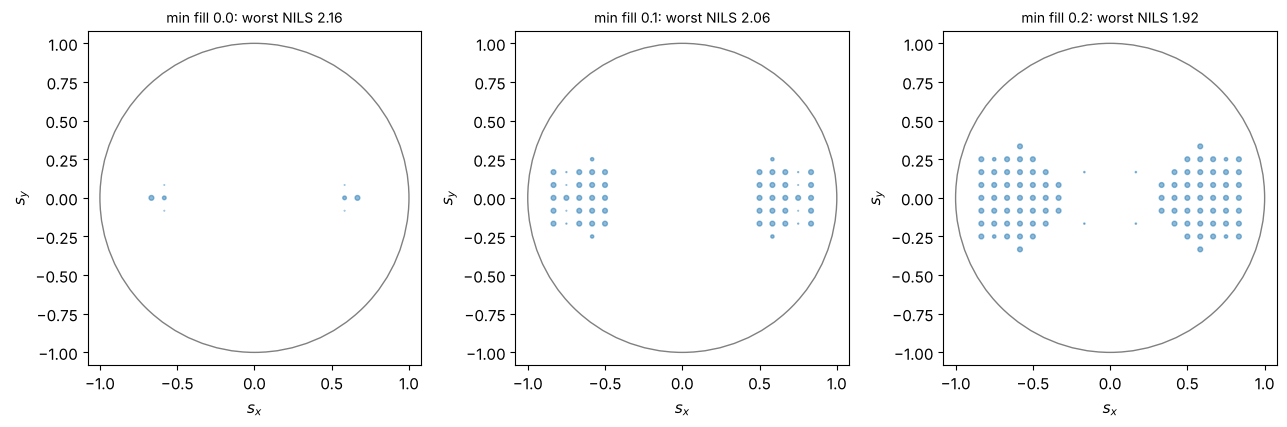

In [4]:
results = {}
for fill in (0.0, 0.1, 0.2):
    t0 = time.time()
    results[fill] = optimizer.optimize(min_fill=fill)
    r = results[fill]
    print("min fill {:.1f}: worst NILS {:.3f}, pupil fill {:.3f}  ({:.2f} s)".format(
        fill, r.worst, r.fill, time.time() - t0))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (fill, r) in zip(axes, results.items()):
    plot_source(r.illumination, ax=ax, show_polarization=False,
                title="min fill {:.1f}: worst NILS {:.2f}".format(fill, r.worst))
plt.tight_layout()

### Against the standard shapes

`scan()` rates families of standard sources with the same metric; here the
best dipole from a grid of radii and opening angles, an annulus and a
conventional source:

best dipole: {'sigma_out': 0.7, 'sigma_in': 0.6, 'opening_angle': 45}, pupil fill 0.032


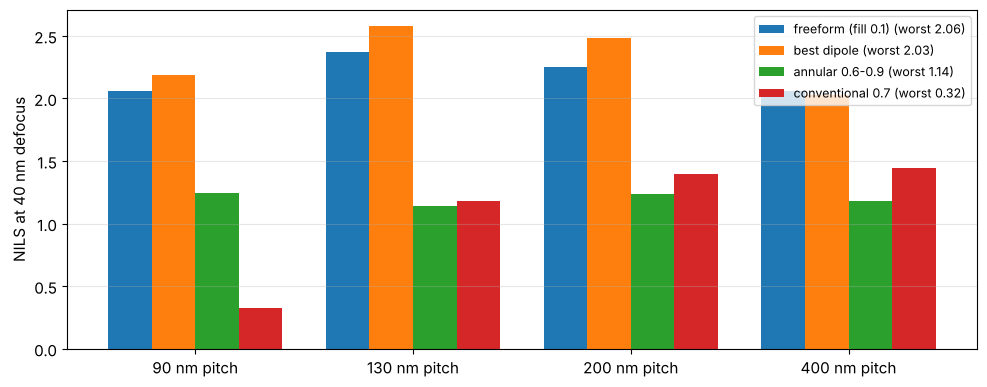

In [5]:
grid = [dict(sigma_out=o, sigma_in=i, opening_angle=a) for o in (0.7, 0.8, 0.9, 0.98)
        for i in (0.3, 0.4, 0.5, 0.6, 0.7) for a in (30, 45, 60, 90) if i < o - 0.05]
best_dipole = so.scan(optimizer, lambda **p: Illumination.dipole(n_samples=N_SAMPLES, polarization=POL,
                                                                  **p), grid)[0]
print("best dipole: {}, pupil fill {:.3f}".format(best_dipole[1],
                                                pixels.fill(optimizer.project(best_dipole[2]))))
sources = {"freeform (fill 0.1)": results[0.1].illumination,
           "best dipole": best_dipole[2],
           "annular 0.6-0.9": Illumination.annular(0.9, 0.6, N_SAMPLES, polarization=POL),
           "conventional 0.7": Illumination.conventional(0.7, N_SAMPLES, polarization=POL)}
nils = {name: optimizer.evaluate(ill) for name, ill in sources.items()}

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(clips))
for i, (name, v) in enumerate(nils.items()):
    ax.bar(x + (i - 1.5)*0.2, v[:, 1], 0.2, label="{} (worst {:.2f})".format(name, v.min()))
ax.set_xticks(x), ax.set_xticklabels(list(clips))
ax.set_ylabel("NILS at 40 nm defocus"), ax.grid(alpha=0.3, axis="y"), ax.legend(fontsize=9)
plt.tight_layout()

The best dipole of the scan comes close to the freeform source. It is
better at 90 to 200 nm and worse at 400 nm, and with its narrow poles it
fills less of the pupil than the 10 % that the freeform source had to
respect. Without that limit the freeform optimum reaches a worst NILS of
2.16. The max–min objective *equalizes* the pitches: the freeform source
gives away NILS where it is plentiful to lift the weakest pitch. The
annulus and the conventional source cannot image the dense pitch well.

### Through focus

The optimization used best focus and 40 nm. A second optimizer with a
finer focus list (only for evaluation; its responses are not needed)
shows the NILS of the worst clip through focus. Freeform and dipole are
close within the optimized focus range and differ only outside of it:

(None, <matplotlib.legend.Legend at 0x7f7cf9dbb9d0>)

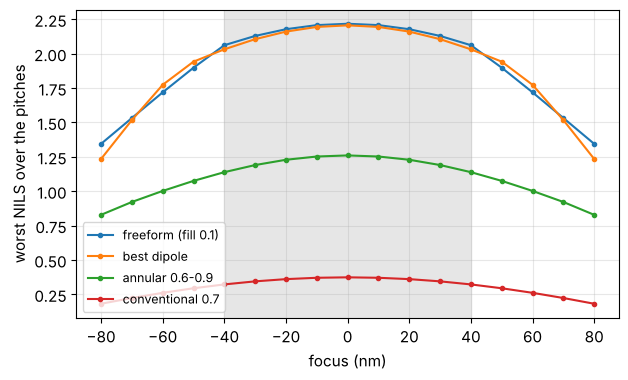

In [6]:
foci = np.linspace(-80, 80, 17)
rating = so.SourceOptimizer(clips, pixels, foci=foci)
fig, ax = plt.subplots(figsize=(7, 4))
for name, ill in sources.items():
    ax.plot(foci, rating.evaluate(ill).min(axis=0), "o-", ms=3, label=name)
ax.axvspan(-40, 40, color="0.9", zorder=0)
ax.set_xlabel("focus (nm)"), ax.set_ylabel("worst NILS over the pitches")
ax.grid(alpha=0.3), ax.legend(fontsize=9)

## 4. A common dose

So far each pitch was assumed to be biased to size on the mask. Without
that, one dose must print all of them: the intensities at their edges
must agree. `dose_tolerance` bounds their relative difference, which turns
into a CD error of about tolerance/NILS relative to the CD. For the two
densest pitches this costs little. For all four pitches, no source keeps
the edge intensities within 5 %; a tolerance of 20 % is feasible but means
a CD error of roughly 20 %/NILS, about 10 % of the CD. Printing dense and
isolated lines at size with one dose is what OPC (mask biasing) is for.

In [7]:
two = {k: clips[k] for k in list(clips)[:2]}
opt_two = so.SourceOptimizer(two, pixels, foci=(0.0, 40.0))
for tol in (None, 0.05, 0.02, 0.0):
    r = opt_two.optimize(min_fill=0.1, dose_tolerance=tol)
    print("90/130 nm, dose tolerance {}: worst NILS {:.3f}, edge intensities {}".format(
        tol, r.worst, np.round(opt_two.edge_intensity(r.weights)[:, 0], 3)))
for tol in (0.05, 0.2):
    try:
        optimizer.optimize(min_fill=0.1, dose_tolerance=tol)
        print("all pitches, dose tolerance {}: feasible".format(tol))
    except ValueError as err:
        print("all pitches, dose tolerance {}: {}".format(tol, err))

90/130 nm, dose tolerance None: worst NILS 2.364, edge intensities [0.285 0.261]
90/130 nm, dose tolerance 0.05: worst NILS 2.356, edge intensities [0.275 0.261]
90/130 nm, dose tolerance 0.02: worst NILS 2.342, edge intensities [0.266 0.261]
90/130 nm, dose tolerance 0.0: worst NILS 2.333, edge intensities [0.261 0.261]
all pitches, dose tolerance 0.05: no source fulfils the constraints (dose_tolerance, min_fill) with positive image slopes at all edges
all pitches, dose tolerance 0.2: feasible


## 5. Lines in both orientations

With vertical and horizontal lines on the same mask the source must serve
both directions. Symmetry about the diagonals (`symmetry="xy-diagonal"`)
makes the source treat them equally. The classic answer is a quadrupole
(poles on the axes) or a quasar (poles on the diagonals); the freeform
optimum shows what the clips actually want:

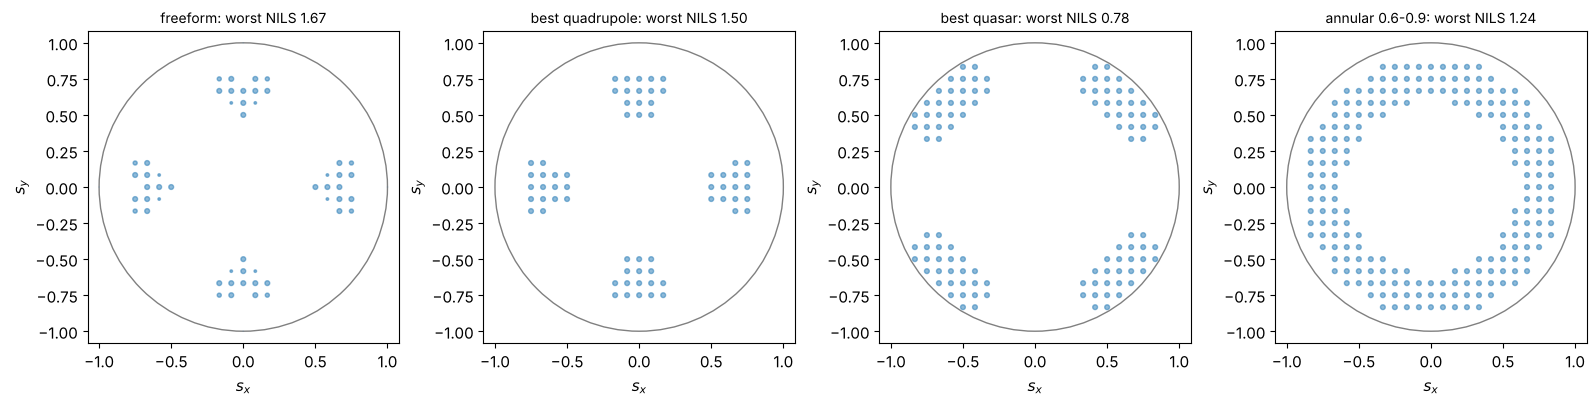

In [8]:
vh = {}
for p in (90.0, 200.0):
    for orientation, label in (("y", "V"), ("x", "H")):
        vh["{} {:.0f}".format(label, p)] = LithoSimulation(
            MaskLayout.lines_spaces(p, 45.0, orientation=orientation), mask, template, projector)
opt_vh = so.SourceOptimizer(vh, so.SourcePixels(N_SAMPLES, symmetry="xy-diagonal"), foci=(0.0, 40.0))
free_vh = opt_vh.optimize(min_fill=0.1)
shape_grid = [dict(sigma_out=o, sigma_in=i, opening_angle=a) for o in (0.8, 0.9, 0.98)
              for i in (0.4, 0.5, 0.6, 0.7) for a in (20, 30, 45) if i < o - 0.05]
candidates = {
    "freeform": (free_vh.worst, free_vh.illumination),
    "best quadrupole": so.scan(opt_vh, lambda **p: Illumination.quadrupole(
        n_samples=N_SAMPLES, polarization=POL, **p), shape_grid)[0][::2],
    "best quasar": so.scan(opt_vh, lambda **p: Illumination.quasar(
        n_samples=N_SAMPLES, polarization=POL, **p), shape_grid)[0][::2],
    "annular 0.6-0.9": (None, Illumination.annular(0.9, 0.6, N_SAMPLES, polarization=POL)),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (name, (worst, ill)) in zip(axes, candidates.items()):
    worst = opt_vh.evaluate(ill).min()
    plot_source(ill, ax=ax, show_polarization=False, title="{}: worst NILS {:.2f}".format(name, worst))
plt.tight_layout()

For two orientations the freeform source puts its light on the axes, close
to a quadrupole with narrow poles, and beats it because it can use pixels
of different weights at different radii for the two pitches. The quasar
puts its poles on the diagonals, where neither orientation finds its
two-beam positions at this dense pitch. That shape suits contact holes and
2D patterns, not dense lines in two directions.

## Summary

- Abbe images are linear in the source weights; `SourceOptimizer` stores
  the responses of every pixel group at the nominal edges and rates any
  source quickly (`nils()`, `project()`), and `evaluate()` checks it with
  the full simulation.
- `optimize()` maximizes the worst NILS over clips and foci by linear
  programming, with symmetry, a minimum pupil fill and an optional common
  dose (`dose_tolerance`).
- `scan()` rates families of standard shapes with the same metric for
  comparison ("freeform to dipole/quadrupole").
- Through pitch, the freeform source lifts the worst pitch above the best
  dipole; a common dose for dense and isolated lines needs OPC.
- Not included: mask optimization (SMO), resist effects, and the
  diffraction from the source pixel shape; NILS at the nominal edges is a
  proxy for the process window.